# Laptop Price Dataset - Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("laptopData.csv")


In [3]:
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1273 non-null   float64
 1   Company           1273 non-null   str    
 2   TypeName          1273 non-null   str    
 3   Inches            1273 non-null   str    
 4   ScreenResolution  1273 non-null   str    
 5   Cpu               1273 non-null   str    
 6   Ram               1273 non-null   str    
 7   Memory            1273 non-null   str    
 8   Gpu               1273 non-null   str    
 9   OpSys             1273 non-null   str    
 10  Weight            1273 non-null   str    
 11  Price             1273 non-null   float64
dtypes: float64(2), str(10)
memory usage: 122.3 KB


In [5]:
df.tail()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
1298,1298.0,Lenovo,2 in 1 Convertible,14,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.64
1299,1299.0,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.72
1300,1300.0,Lenovo,Notebook,14,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.12
1301,1301.0,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.92
1302,1302.0,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.32


## Cleaning
Drop the empty index column and rows that are completely blank, then convert `Ram`, `Weight` and `Inches` into numeric columns.

In [6]:
df = df.drop(columns=["Unnamed: 0"])
df = df.dropna(how="all")

df["Ram"] = pd.to_numeric(df["Ram"].astype(str).str.replace("GB", "", regex=False), errors="coerce")
df["Weight"] = pd.to_numeric(df["Weight"].astype(str).str.replace("kg", "", regex=False), errors="coerce")
df["Inches"] = pd.to_numeric(df["Inches"], errors="coerce")

df = df.dropna(subset=["Ram", "Weight", "Inches", "Price"])
df.head()


,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080


In [7]:
df.info()

<class 'pandas.DataFrame'>
Index: 1271 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1271 non-null   str    
 1   TypeName          1271 non-null   str    
 2   Inches            1271 non-null   float64
 3   ScreenResolution  1271 non-null   str    
 4   Cpu               1271 non-null   str    
 5   Ram               1271 non-null   int64  
 6   Memory            1271 non-null   str    
 7   Gpu               1271 non-null   str    
 8   OpSys             1271 non-null   str    
 9   Weight            1271 non-null   float64
 10  Price             1271 non-null   float64
dtypes: float64(3), int64(1), str(7)
memory usage: 119.2 KB


In [8]:
df["Company"].value_counts()

Company
Lenovo       290
Dell         285
HP           266
Asus         156
Acer         103
MSI           53
Toshiba       47
Apple         21
Samsung        9
Razer          7
Mediacom       7
Microsoft      6
Xiaomi         4
Vero           4
Chuwi          3
Google         3
LG             3
Huawei         2
Fujitsu        2
Name: count, dtype: int64

In [9]:
df["TypeName"].value_counts()

TypeName
Notebook              710
Gaming                203
Ultrabook             190
2 in 1 Convertible    116
Workstation            28
Netbook                24
Name: count, dtype: int64

In [10]:
df["OpSys"].value_counts()

OpSys
Windows 10      1045
No OS             63
Linux             61
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            1
Name: count, dtype: int64

In [11]:
df["Ram"].value_counts().sort_index()

Ram
1       1
2      22
4     367
6      40
8     599
12     25
16    194
24      3
32     17
64      3
Name: count, dtype: int64

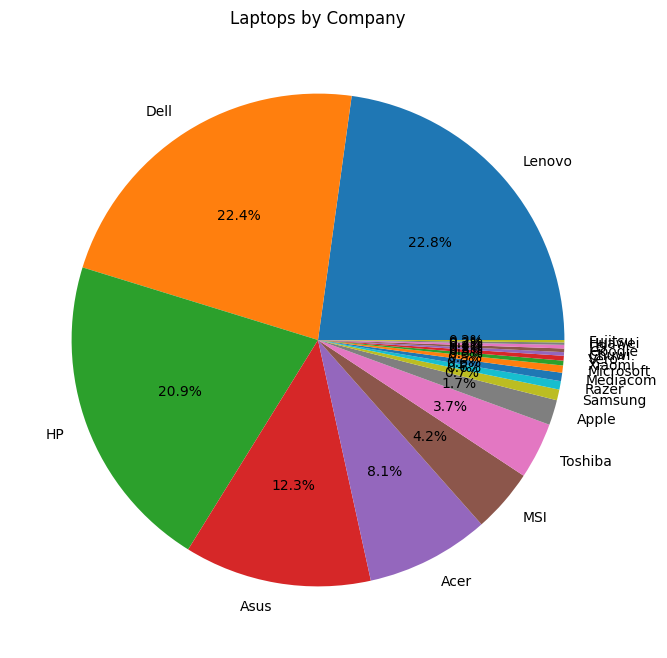

In [12]:
Company = df['Company'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(Company, labels=Company.index, autopct='%1.1f%%')
plt.title('Laptops by Company')
plt.show()


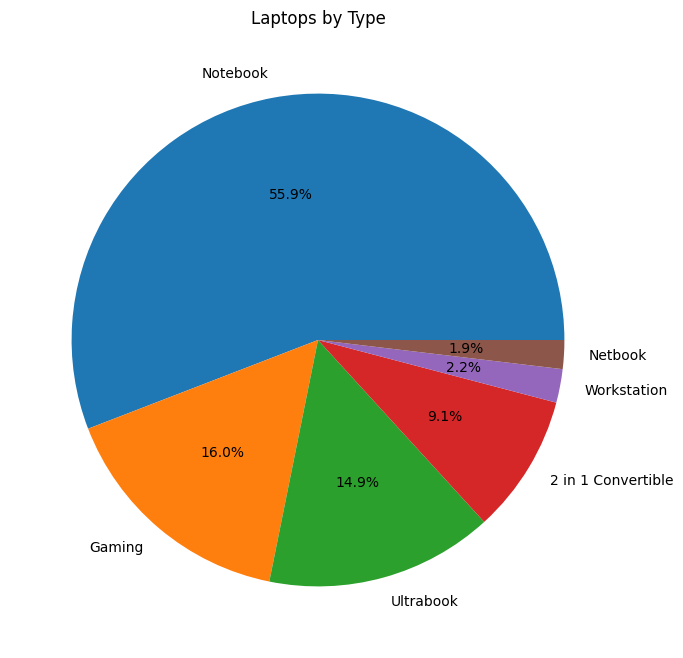

In [13]:
TypeName = df['TypeName'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(TypeName, labels=TypeName.index, autopct='%1.1f%%')
plt.title('Laptops by Type')
plt.show()


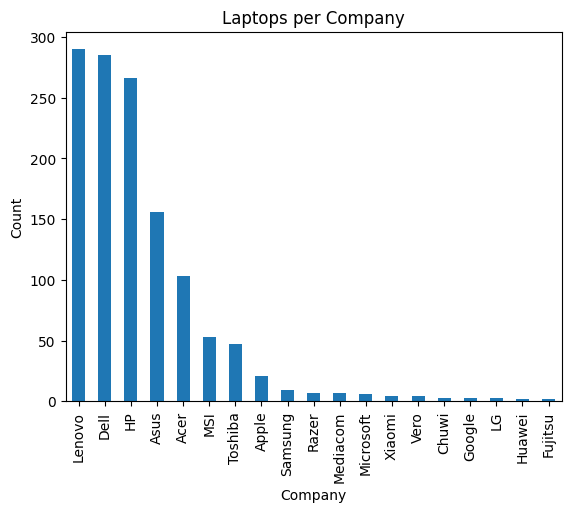

In [14]:
comp_cnt = df['Company'].value_counts()
comp_cnt.plot(kind='bar')
plt.title("Laptops per Company")
plt.xlabel("Company")
plt.ylabel("Count")
plt.show()


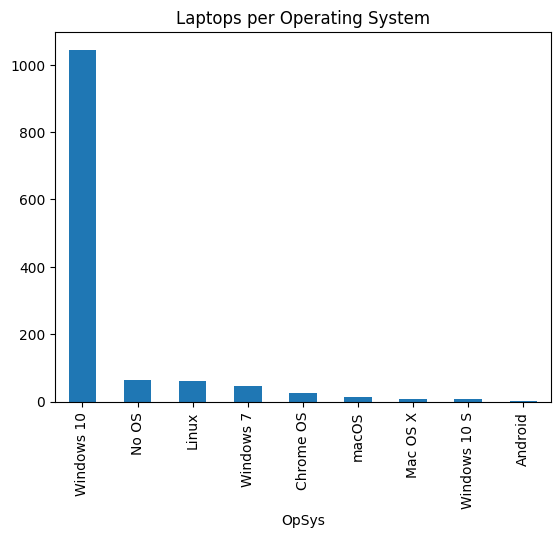

In [15]:
os_cnt = df['OpSys'].value_counts()
os_cnt.plot(kind='bar')
plt.title("Laptops per Operating System")
plt.xlabel("OpSys")
plt.show()


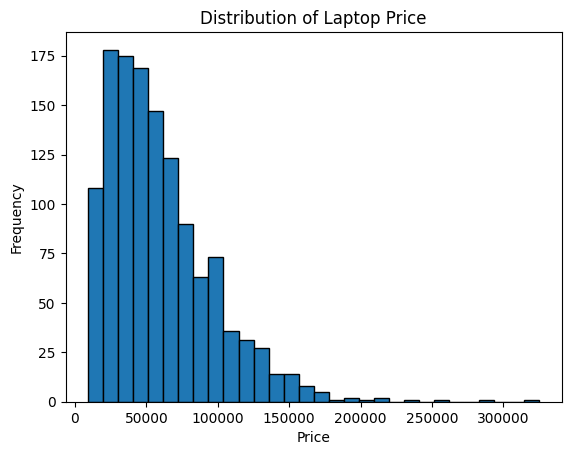

In [16]:
df["Price"].plot(kind="hist", bins=30, edgecolor="black")
plt.title("Distribution of Laptop Price")
plt.xlabel("Price")
plt.show()


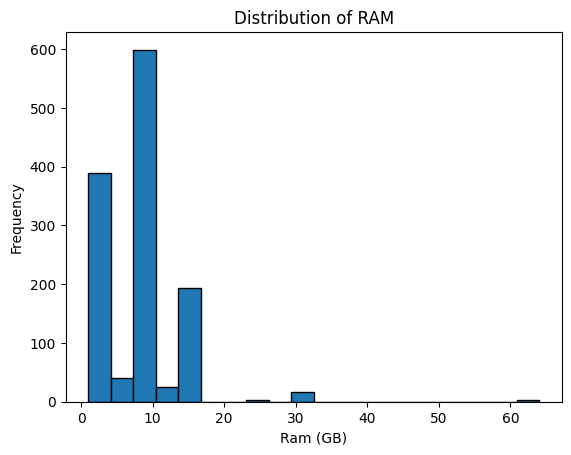

In [17]:
df["Ram"].plot(kind="hist", bins=20, edgecolor="black")
plt.title("Distribution of RAM")
plt.xlabel("Ram (GB)")
plt.show()


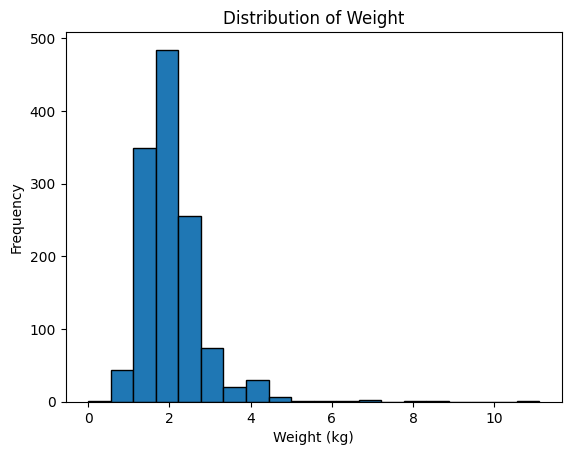

In [18]:
df["Weight"].plot(kind="hist", bins=20, edgecolor="black")
plt.title("Distribution of Weight")
plt.xlabel("Weight (kg)")
plt.show()


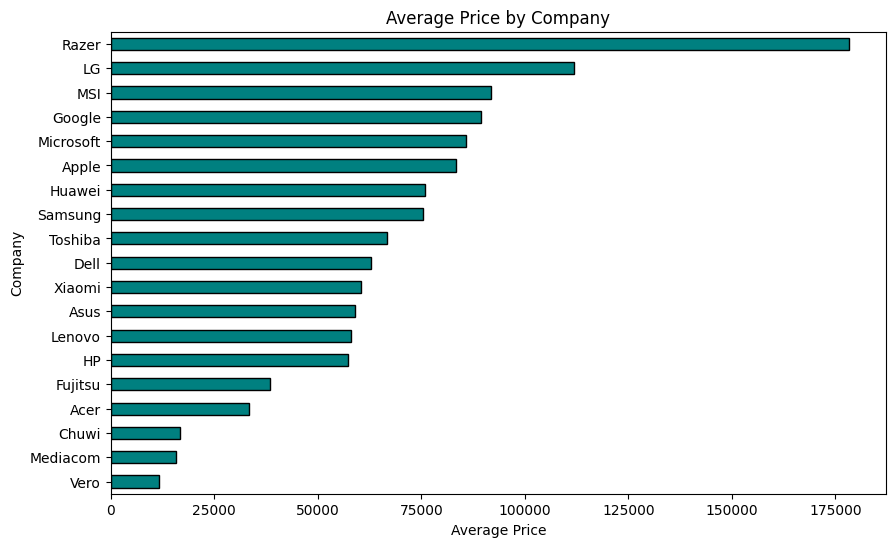

In [19]:
avg_price_company = df.groupby('Company')['Price'].mean().sort_values()

plt.figure(figsize=(10, 6))
avg_price_company.plot(kind='barh', color='teal', edgecolor='black')
plt.title('Average Price by Company')
plt.xlabel('Average Price')
plt.show()


In [20]:
Price_stats = df.groupby("TypeName")["Price"].agg(["max", "min", "mean"])
Price_stats


,max,min,mean
TypeName,,,
2 in 1 Convertible,137995.20,14652.00,68186.738110
Gaming,324954.72,37242.72,92204.328662
Netbook,101658.24,9270.72,34884.858000
Notebook,261018.72,10442.88,41545.173052
Ultrabook,165168.00,26586.72,82956.160800
Workstation,233845.92,72940.32,121254.643029


In [21]:
Ram_stats = df.groupby("Company")["Ram"].agg(["max", "min", "mean"])
Ram_stats


,max,min,mean
Company,,,
Acer,16,1,5.854369
Apple,16,4,9.333333
Asus,64,2,9.602564
Chuwi,6,4,4.666667
Dell,64,2,9.354386
Fujitsu,8,4,6.000000
Google,16,8,10.666667
HP,16,2,6.932331
Huawei,8,8,8.000000


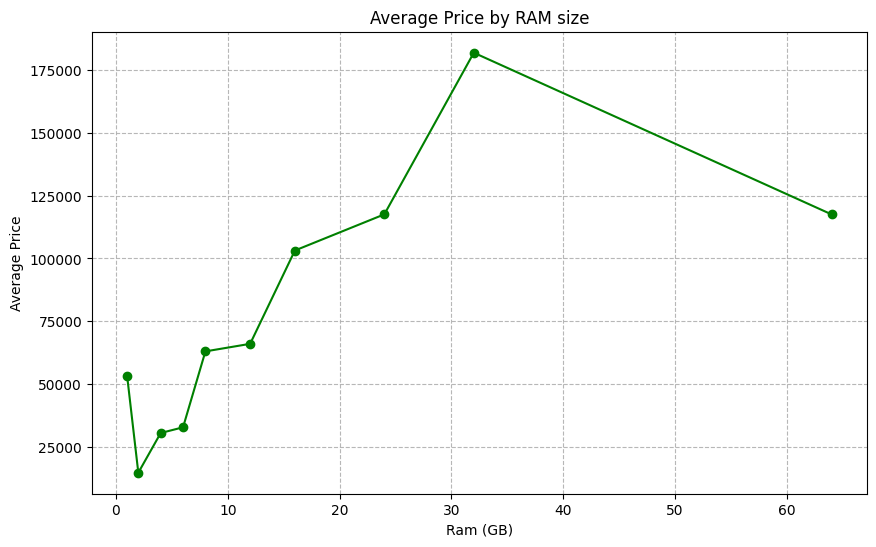

In [22]:
avg_price_ram = df.groupby('Ram')['Price'].mean()

plt.figure(figsize=(10, 6))
plt.plot(avg_price_ram.index, avg_price_ram.values, marker='o', linestyle='-', color='green')
plt.title('Average Price by RAM size')
plt.xlabel('Ram (GB)')
plt.ylabel('Average Price')
plt.grid(True, linestyle='--', alpha=0.9)
plt.show()


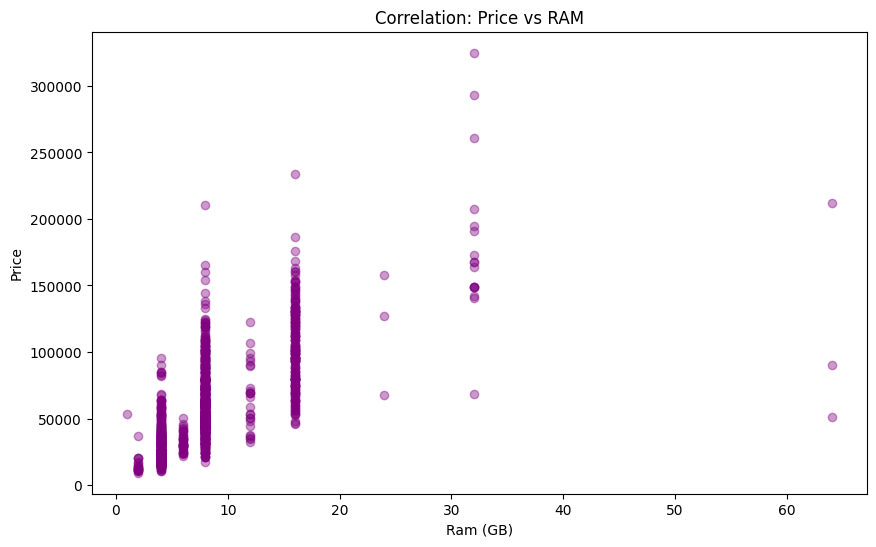

In [23]:
plt.figure(figsize=(10, 6))
plt.scatter(df['Ram'], df['Price'], alpha=0.4, color='purple')
plt.title('Correlation: Price vs RAM')
plt.xlabel('Ram (GB)')
plt.ylabel('Price')
plt.show()


<Figure size 1000x600 with 0 Axes>

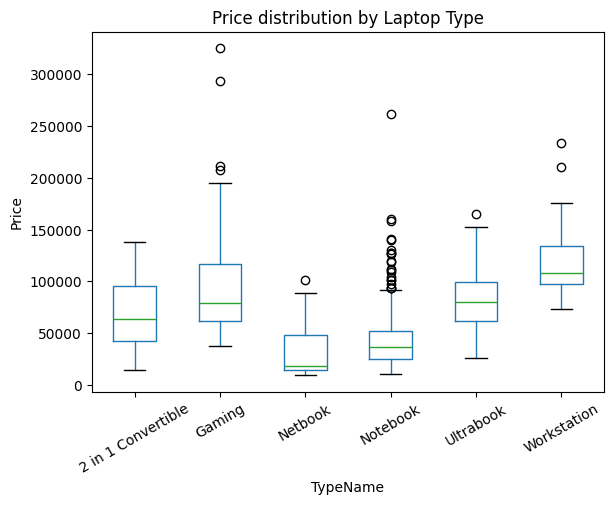

In [24]:
plt.figure(figsize=(10,6))
df.boxplot(column='Price', by='TypeName', grid=False)
plt.title('Price distribution by Laptop Type')
plt.suptitle('')
plt.ylabel('Price')
plt.xticks(rotation=30)
plt.show()


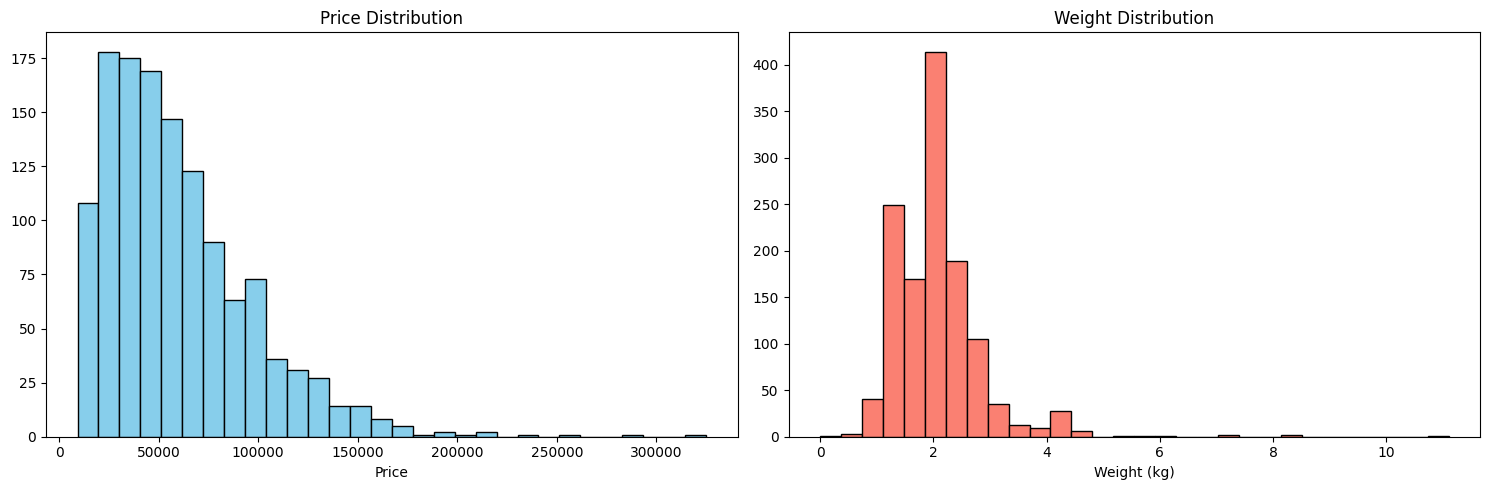

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(df['Price'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('Price Distribution')
axes[0].set_xlabel('Price')

axes[1].hist(df['Weight'], bins=30, color='salmon', edgecolor='black')
axes[1].set_title('Weight Distribution')
axes[1].set_xlabel('Weight (kg)')

plt.tight_layout()
plt.show()


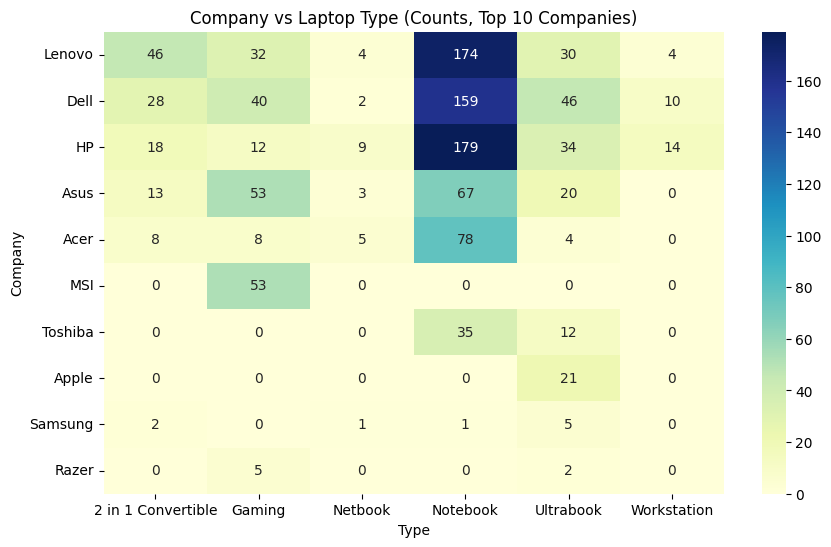

In [26]:
top_types = df['Company'].value_counts().head(10)
ct_company_type = pd.crosstab(df['Company'], df['TypeName'])
ct_company_type = ct_company_type.loc[top_types.index]

plt.figure(figsize=(10, 6))
sns.heatmap(ct_company_type, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Company vs Laptop Type (Counts, Top 10 Companies)")
plt.xlabel("Type")
plt.ylabel("Company")
plt.show()


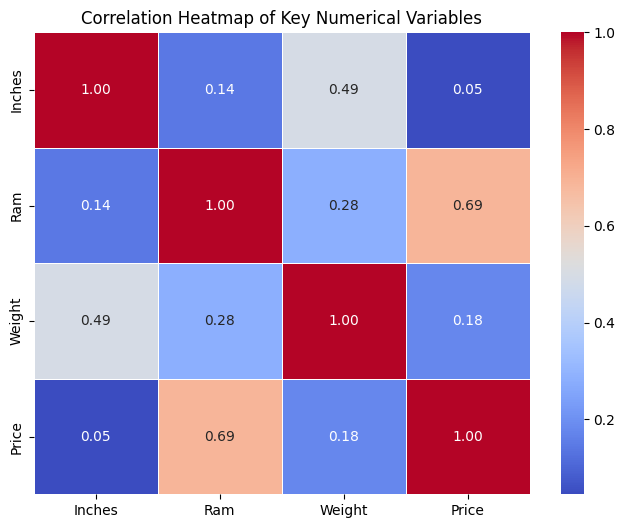

In [27]:
num_cols = ['Inches', 'Ram', 'Weight', 'Price']
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title('Correlation Heatmap of Key Numerical Variables')
plt.show()


In [28]:
company_price_pivot = df.pivot_table(values="Price", index="Company", aggfunc=["max", "mean", "min"])
company_price_pivot


,max,mean,min
,Price,Price,Price
Company,,,
Acer,138474.720,33394.615969,9270.7200
Apple,152274.240,83340.499886,47895.5232
Asus,211788.000,58972.373723,10602.7200
Chuwi,23922.720,16745.726400,13053.0672
Dell,194972.832,62959.773928,14646.6720
Fujitsu,42570.720,38574.720000,34578.7200
Google,117162.720,89386.080000,67932.0000
HP,233845.920,57214.371465,11135.5200


In [29]:
total_records = len(df)
avg_price = df["Price"].mean()
avg_ram = df["Ram"].mean()
top_company = df["Company"].value_counts().idxmax()
priciest_type = df.groupby("TypeName")["Price"].mean().idxmax()
touchscreen_pct = (df["ScreenResolution"].str.contains("Touchscreen", na=False).sum() / total_records) * 100

print("Total laptops analysed:", total_records)
print("Average price:", round(avg_price, 2))
print("Average RAM (GB):", round(avg_ram, 2))
print("Most common company:", top_company)
print("Most expensive type on average:", priciest_type)
print("Percentage with a touchscreen:", round(touchscreen_pct, 2), "%")


Total laptops analysed: 1271
Average price: 59888.47
Average RAM (GB): 8.46
Most common company: Lenovo
Most expensive type on average: Workstation
Percentage with a touchscreen: 14.56 %


In [30]:
price = df['Price'].to_numpy()
ram = df['Ram'].to_numpy()
weight = df['Weight'].to_numpy()
inches = df['Inches'].to_numpy()

print("Price:", price[:5])
print("Ram:", ram[:5])
print("Weight:", weight[:5])
print("Inches:", inches[:5])
print("Price dtype:", price.dtype)


Price: [ 71378.6832  47895.5232  30636.     135195.336   96095.808 ]
Ram: [ 8  8  8 16  8]
Weight: [1.37 1.34 1.86 1.83 1.37]
Inches: [13.3 13.3 15.6 15.4 13.3]
Price dtype: float64


In [31]:
print("Average Price is:", round(np.mean(price), 2))
print("Highest Price found is:", np.max(price))
print("Lowest Price found is:", np.min(price))
print("Average RAM is:", round(np.mean(ram), 2))
print("Highest RAM found is:", np.max(ram))


Average Price is: 59888.47
Highest Price found is: 324954.72
Lowest Price found is: 9270.72
Average RAM is: 8.46
Highest RAM found is: 64


In [32]:
columns = [price, ram, weight, inches]
column_names = ["Price", "Ram", "Weight", "Inches"]

summary_list = []
for data in columns:
    stats = {
        "Mean (Avg)": round(np.mean(data), 2),
        "Std Dev (Spread)": round(np.std(data), 2),
        "Total (Sum)": round(np.sum(data), 2),
        "Highest (Max)": np.max(data),
        "Lowest (Min)": np.min(data),
        "Count": len(data),
    }
    summary_list.append(stats)

summary_table = pd.DataFrame(summary_list, index=column_names)
summary_table


,Mean (Avg),Std Dev (Spread),Total (Sum),Highest (Max),Lowest (Min),Count
Price,59888.47,37294.51,76118250.36,324954.72,9270.7200,1271
Ram,8.46,5.57,10757.00,64.00,1.0000,1271
Weight,2.08,0.81,2640.95,11.10,0.0002,1271
Inches,15.13,1.95,19233.10,35.60,10.1000,1271


In [33]:
summary_table.to_csv("laptop_summary.csv")
print("Saved summary table to laptop_summary.csv")


Saved summary table to laptop_summary.csv
